In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config import AUDIO_FEATURES
from data import load_data, clean_data

df = load_data()
df_clean = clean_data(df)

2026-10-29 10:33:40.809 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 10:33:40.811 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 10:33:40.812 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 10:33:40.813 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-29 10:33:42.966 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 10:33:43.048 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [2]:
# 🎓 Projet Machine Learning n°2 — Spotify : décrypter la musique 🎧
# 1. **Structure** : dimensions, types, valeurs manquantes.
print("Dimensions :", df.shape)

df.info()

print(df.isnull().sum())

df.describe()

Dimensions : (32833, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-

,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000
mean,42.477081,0.654850,0.698619,5.374471,-6.719499,0.565711,0.107068,0.175334,0.084747,0.190176,0.510561,120.881132,225799.811622
std,24.984074,0.145085,0.180910,3.611657,2.988436,0.495671,0.101314,0.219633,0.224230,0.154317,0.233146,26.903624,59834.006182
min,0.000000,0.000000,0.000175,0.000000,-46.448000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000.000000
25%,24.000000,0.563000,0.581000,2.000000,-8.171000,0.000000,0.041000,0.015100,0.000000,0.092700,0.331000,99.960000,187819.000000
50%,45.000000,0.672000,0.721000,6.000000,-6.166000,1.000000,0.062500,0.080400,0.000016,0.127000,0.512000,121.984000,216000.000000
75%,62.000000,0.761000,0.840000,9.000000,-4.645000,1.000000,0.132000,0.255000,0.004830,0.248000,0.693000,133.918000,253585.000000
max,100.000000,0.983000,1.000000,11.000000,1.275000,1.000000,0.918000,0.994000,0.994000,0.996000,0.991000,239.440000,517810.000000


In [3]:
# 2. **Doublons** :
print("Nombre de lignes :", len(df))
print("Morceaux uniques :", df["track_id"].nunique())

nb_genres = df.groupby("track_id")["playlist_genre"].nunique()

print("Morceaux avec plusieurs genres :", (nb_genres > 1).sum())

Nombre de lignes : 32833
Morceaux uniques : 28356
Morceaux avec plusieurs genres : 1687


In [4]:
# 3. **Changements de types et nouvelles variables** :

print(df_clean[["release_year", "duration_min", "playlist_genre"]].head())

print(df_clean.dtypes)

print("Doublons restants :", df_clean["track_id"].duplicated().sum())

       release_year  duration_min playlist_genre
1551           2019      3.490633            pop
20092          2019      2.727267          latin
687            2019      3.349333            pop
711            2019      3.158100            pop
716            2019      3.359550            pop
track_id                      object
track_name                    object
track_artist                  object
track_popularity               int64
track_album_id                object
track_album_name              object
track_album_release_date      object
playlist_name                 object
playlist_id                   object
playlist_genre              category
playlist_subgenre             object
danceability                 float64
energy                       float64
key                            int64
loudness                     float64
mode                           int64
speechiness                  float64
acousticness                 float64
instrumentalness             float64
liv

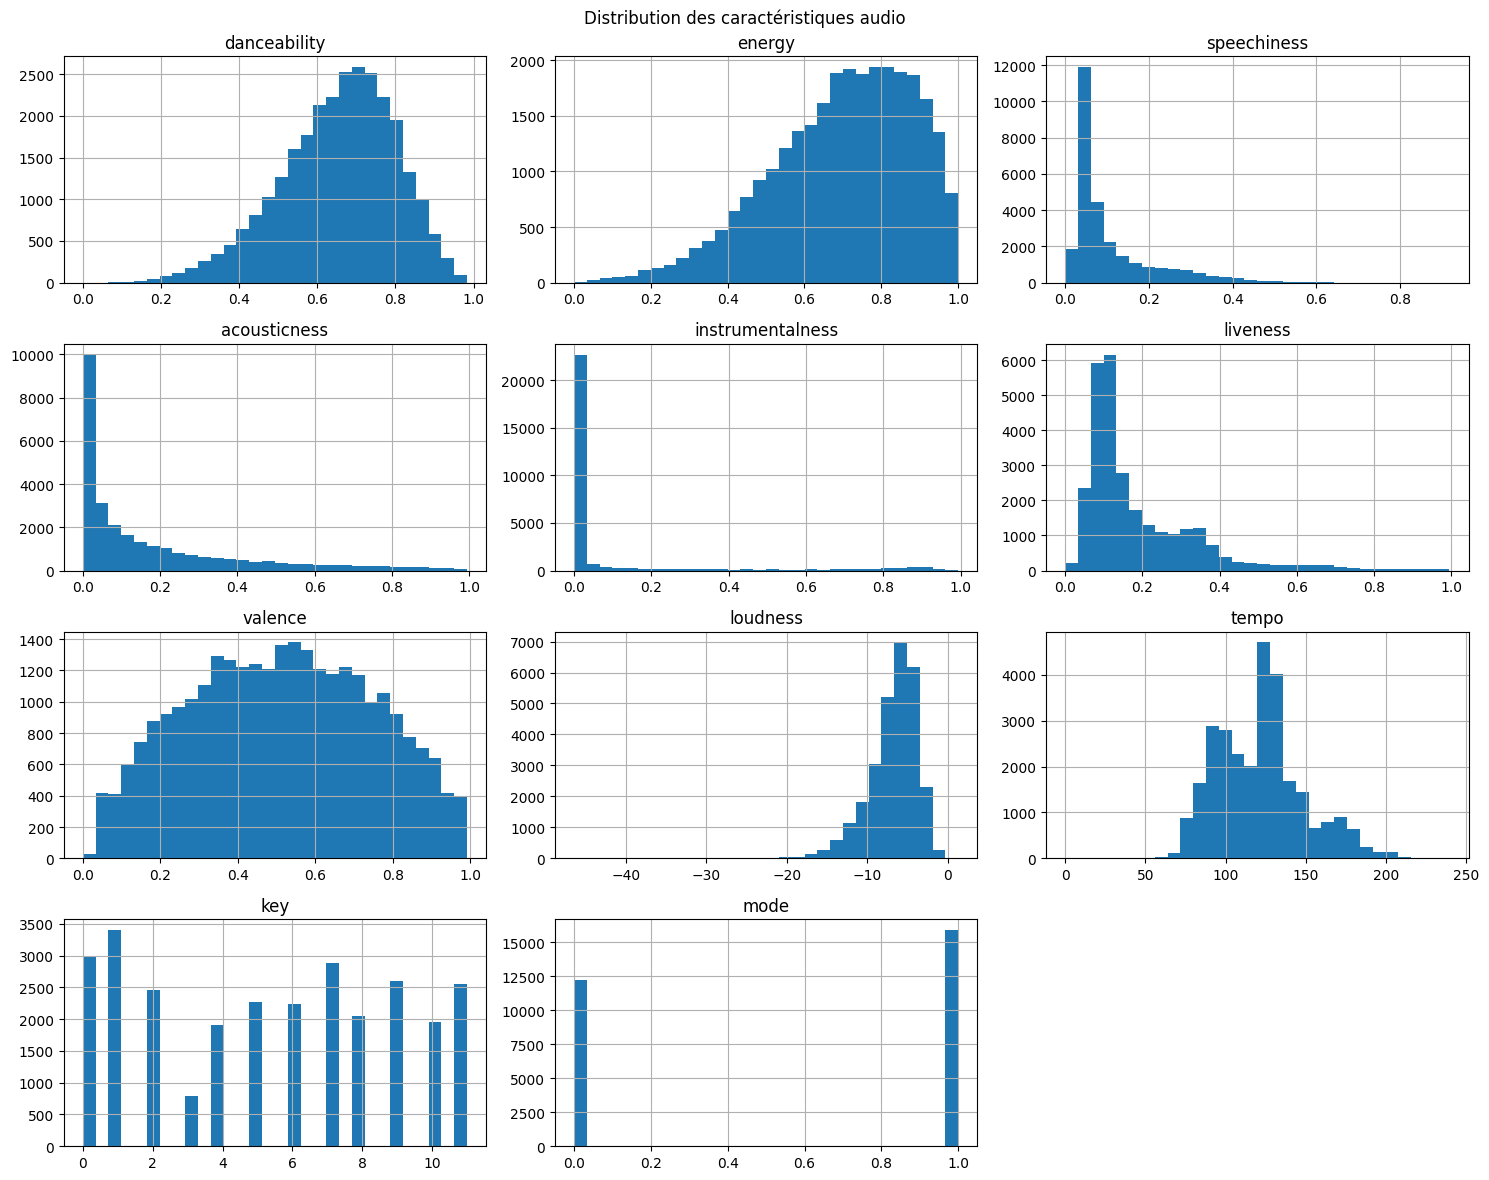

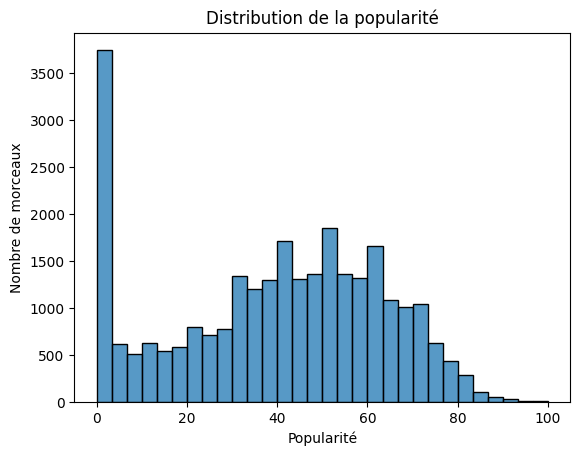

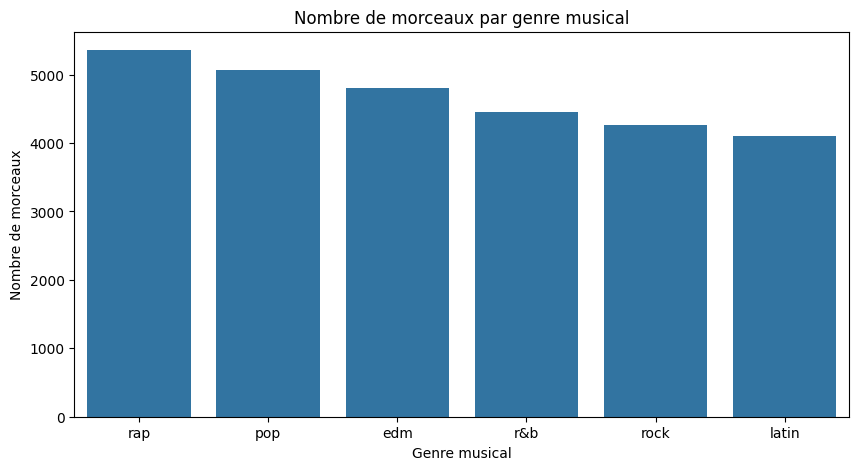

playlist_genre
rap      5360
pop      5067
edm      4811
r&b      4458
rock     4270
latin    4102
Name: count, dtype: int64


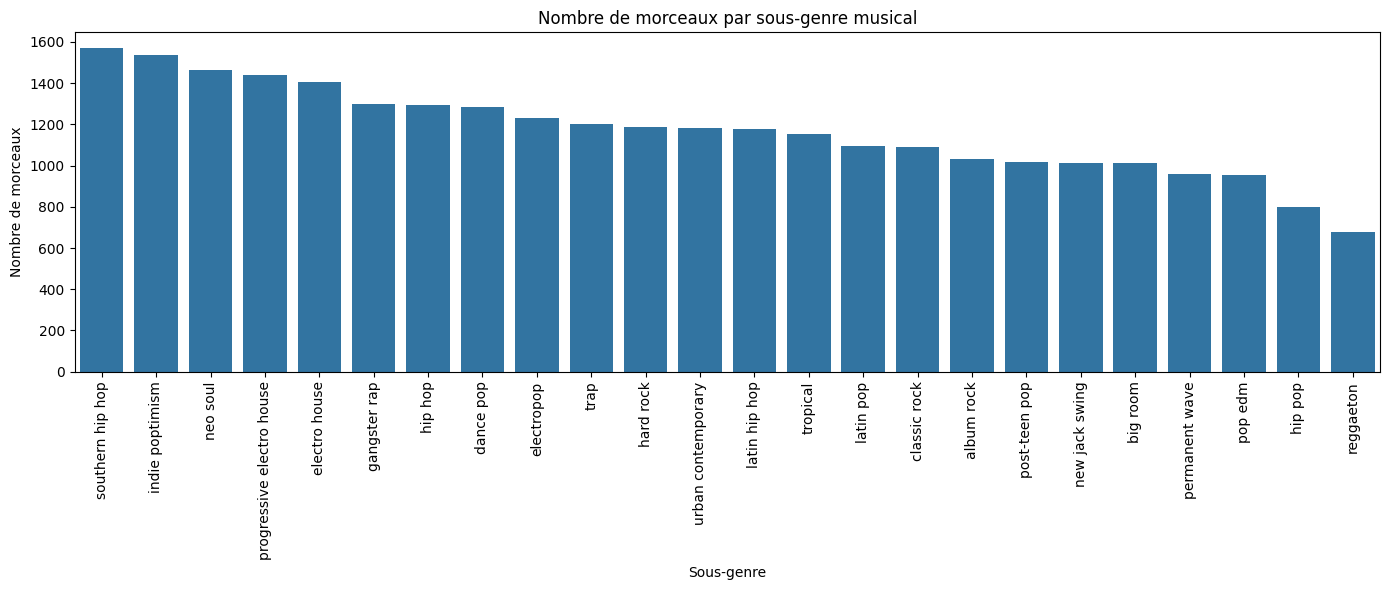

In [5]:
# 4. Analyse univariée : caractéristiques audio

df_clean[AUDIO_FEATURES].hist(
    figsize=(15, 12),
    bins=30
)

plt.suptitle("Distribution des caractéristiques audio")
plt.tight_layout()
plt.show()

sns.histplot(data=df_clean, x="track_popularity", bins=30)

plt.title("Distribution de la popularité")
plt.xlabel("Popularité")
plt.ylabel("Nombre de morceaux")
plt.show()


# 4.4 Nombre de morceaux par genre

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="playlist_genre",
    order=df_clean["playlist_genre"].value_counts().index
)

plt.title("Nombre de morceaux par genre musical")
plt.xlabel("Genre musical")
plt.ylabel("Nombre de morceaux")
plt.show()

# Afficher les valeurs exactes
print(df_clean["playlist_genre"].value_counts())

# 4.5 Nombre de morceaux par sous-genre

plt.figure(figsize=(14, 6))

sns.countplot(
    data=df_clean,
    x="playlist_subgenre",
    order=df_clean["playlist_subgenre"].value_counts().index
)

plt.title("Nombre de morceaux par sous-genre musical")
plt.xlabel("Sous-genre")
plt.ylabel("Nombre de morceaux")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Caractéristiques audio :

Les morceaux Spotify présentent généralement une énergie (energy) et une capacité à danser (danceability) assez élevées. En revanche, les valeurs de speechiness, acousticness et instrumentalness sont souvent proches de zéro.

Le tempo (tempo) se situe principalement entre 90 et 140 BPM. La variable valence, qui représente le caractère positif d'une musique, est assez bien répartie entre 0 et 1.

Popularité :

La popularité des morceaux se concentre principalement entre 30 et 70. On observe également un nombre important de morceaux ayant une popularité égale à zéro.

Il serait intéressant de vérifier pourquoi autant de morceaux ont cette valeur. Le graphique seul ne permet pas de savoir s'il s'agit réellement de morceaux peu populaires ou de valeurs particulières du dataset.

In [9]:
# Vérification des doublons après nettoyage

cles = [
    "track_artist",
    "track_name",
    "track_album_name",
    "duration_ms"
]

# Doublons avec le même track_id
print("Doublons track_id :",
      df_clean.duplicated(subset=["track_id"]).sum())

# Doublons avec les mêmes informations et caractéristiques audio
print("Doublons audio identique :",
      df_clean.duplicated(subset=cles + AUDIO_FEATURES).sum())

# Morceaux ayant le même titre/album/durée mais un audio différent
groupes = df_clean.groupby(cles, dropna=False)

ids = groupes["track_id"].nunique()

print("Groupes avec plusieurs track_id :", (ids > 1).sum())

print("Nombre de morceaux conservés :", len(df_clean))

Doublons track_id : 0
Doublons audio identique : 0
Groupes avec plusieurs track_id : 274
Nombre de morceaux conservés : 28068


In [7]:
# Tous les morceaux de 50 Cent
fifty = df_clean[
    df_clean["track_artist"].str.lower() == "50 cent"
]

# Afficher leurs titres, albums et popularités
display(
    fifty[
        ["track_name", "track_album_name", "release_year",
         "track_popularity", "track_id"]
    ].sort_values("track_popularity")
)

# Rechercher d'autres versions des titres ayant une popularité de 0
titres_zero = fifty.loc[
    fifty["track_popularity"] == 0, "track_name"
].str.lower()

autres_versions = df_clean[
    (df_clean["track_artist"].str.lower() == "50 cent") &
    (df_clean["track_name"].str.lower().isin(titres_zero)) &
    (df_clean["track_popularity"] > 0)
]

print("Autres versions avec une popularité positive :")
display(
    autres_versions[
        ["track_name", "track_album_name", "track_popularity", "track_id"]
    ]
)

,track_name,track_album_name,release_year,track_popularity,track_id
9170,Disco Inferno,Best Of 50 Cent,2017,0,2MzLi4EopILqoDTZuLtIzW
7910,GATman And Robbin,The Massacre (Ecopac Reissue Explicit),2005,0,0mMmhuNtbJalQCZy5VhVwk
7911,"OK, You're Right",Before I Self-Destruct,2009,0,6so3XYH1yyeWFGskbQvDjQ
8520,My Gun Go Off,Curtis,2007,0,5YT6EzwPldMABUP2C2mAAz
8535,I Got Swag,Before I Self-Destruct,2009,0,47dwmBX3P67PZj8147Oqbd
8540,If I Can't,Get Rich Or Die Tryin' (Explicit Version),2003,0,6vcIFbbIOVfek0Npl2t1qq
8566,Outlaw,Outlaw,2011,0,6m3blCKBMVimP5y8bTndD5
8572,Crime Wave,Before I Self-Destruct,2009,0,0gDh8XfKdq9of5fxuyayq2
8544,Disco Inferno - Live from Sessions @ AOL,Just A Lil Bit (International Version),2005,0,0ctMHnma5rklnfurOKFXV0
8605,Disco Inferno,Candy Shop (International Version),2005,0,12MDB5ARcX4wYVS1RnnRA1


Autres versions avec une popularité positive :


,track_name,track_album_name,track_popularity,track_id
7948,If I Can't,Get Rich Or Die Tryin',65,6mcu7D7QuABVwUGDwovOEh


Decouverte qu'il peut y avoir des doublons avec un track_id différent

In [8]:
# Comparer les deux versions de Just A Lil Bit

morceaux = df_clean[
    (df_clean["track_artist"] == "50 Cent") &
    (df_clean["track_name"] == "Just A Lil Bit")
]

colonnes = [
    "track_id", "track_name", "track_album_name",
    "track_popularity", "duration_ms",
    "danceability", "energy", "loudness",
    "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo", "key", "mode"
]

display(morceaux[colonnes].T)

,9155,6051,8543
track_id,4nva9EpKntUTs6CRSGBCn9,68IM0wOuxlrbwk0zgmi9dk,2JxeAupAiJdB8I2cieG4rP
track_name,Just A Lil Bit,Just A Lil Bit,Just A Lil Bit
track_album_name,The Massacre,The Massacre,The Massacre
track_popularity,75,3,2
duration_ms,237707,237707,237707
danceability,0.489,0.724,0.704
energy,0.692,0.692,0.683
loudness,-6.672,-6.75,-6.617
speechiness,0.41,0.324,0.328
acousticness,0.0322,0.0397,0.0326


10:00 : MOdification du fichier data.py pour supprimer les doublon en fonction du titre/artiste/album et garder celui avec la meilleur pop